# Dummy Regressor: Property Asking-Price Prediction

## 1. Title and Objective

Establish a feature-independent reference using the arithmetic mean training asking price.

Source: [vduydong/vietnam-real-estates](https://huggingface.co/datasets/vduydong/vietnam-real-estates), revision `a9a66ffa985edcf76b4be59ae2c6f5b1db889c38`. The dataset credits TiniX AI and specifies CC BY-NC 4.0. The outcome is the recorded asking price in VND, not a verified transaction price.

## 2. Experimental Setup

Run `python -m experiments.prepare` once from the repository root. This notebook then executes independently from the repository root or `models/`, uses the frozen cohort, and never downloads data implicitly. Exact dependencies are recorded in `requirements-experiments-lock.txt`.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "experiments").is_dir() and (path / "requirements.txt").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from experiments.data import load_data, SEED, NUMERIC, CATEGORICAL
from experiments.evaluation import (
    select_candidate, inverse_log, record_result, diagnostics,
    importance_plot, comparison_table, environment,
)
from experiments.estimators import (
    structured_preprocessor, native_features, catboost_features,
    text_pipeline, MedianPricePerSqm,
)

np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.dpi": 300})
parts, manifest = load_data()
train, validation, test = (parts[name] for name in ["train", "validation", "test"])
y_train = train.price.to_numpy()
y_validation = validation.price.to_numpy()
log_y_train = np.log1p(y_train)
log_y_validation = np.log1p(y_validation)
display(pd.Series({"Seed": SEED, "Dataset": manifest["source"]["dataset"],
                   "Revision": manifest["source"]["revision"],
                   "Split SHA-256": manifest["split_sha256"]}, name="Setting").to_frame())
display(pd.Series(environment()["packages"], name="Installed version").to_frame())

,Setting
Seed,42
Dataset,vduydong/vietnam-real-estates
Revision,a9a66ffa985edcf76b4be59ae2c6f5b1db889c38
Split SHA-256,15340296092993fac87fe7f2cd02c9635da706a0510a79...


,Installed version
numpy,1.26.4
pandas,2.2.3
pyarrow,18.1.0
scikit-learn,1.5.2
lightgbm,4.5.0
catboost,1.2.7
matplotlib,3.9.2


## 3. Dataset Overview

The following tables are computed from the verified cohort. Feature missingness and price summaries describe training data only.

In [2]:
display(pd.DataFrame([
    {"Split": name, "Listings": len(frame),
     "First publication (UTC)": frame.published_at.min(),
     "Last publication (UTC)": frame.published_at.max()}
    for name, frame in parts.items()
]).set_index("Split"))
display(pd.DataFrame({"Training dtype": train[NUMERIC + CATEGORICAL].dtypes.astype(str),
                      "Training missing fraction": train[NUMERIC + CATEGORICAL].replace(
                          "__MISSING__", np.nan).isna().mean()}))
display(train.price.describe(percentiles=[.01, .5, .99]).rename("Training asking price (VND)").to_frame())
display(Markdown(
    f"All {manifest['counts']['raw_rows']:,} source rows were inspected; "
    f"{manifest['counts']['eligible_rows']:,} were eligible. A fixed-seed uniform sample of "
    f"{manifest['sampled_rows_before_deduplication']:,} eligible rows was drawn across all five shards. "
    f"Removing {manifest['sample_duplicates_removed']:,} repeated identity proxies left "
    f"{manifest['cohort_rows']:,} listings. These are sample-based experiments, not full-corpus model fits."
))

,Listings,First publication (UTC),Last publication (UTC)
Split,,,
train,41663,2025-06-01 01:25:24.427000+00:00,2025-11-04 13:39:57.561000+00:00
validation,8928,2025-11-04 13:44:57.945000+00:00,2025-12-02 22:12:39.046000+00:00
test,8928,2025-12-02 22:13:20.406000+00:00,2025-12-30 23:48:26.266000+00:00


,Training dtype,Training missing fraction
area,float64,0.000000
floor_count,float64,0.765763
frontage_width,float64,0.463913
house_depth,float64,0.975446
road_width,float64,0.818664
bedroom_count,float64,0.468401
bathroom_count,float64,0.501596
property_type_name,object,0.000000
province_name,object,0.000000
district_name,object,0.024170


,Training asking price (VND)
count,4.166300e+04
mean,1.622745e+10
std,9.883617e+10
min,3.200000e+06
1%,5.500000e+08
50%,7.400000e+09
99%,1.300000e+11
max,1.120000e+13


All 1,000,000 source rows were inspected; 915,657 were eligible. A fixed-seed uniform sample of 60,000 eligible rows was drawn across all five shards. Removing 481 repeated identity proxies left 59,519 listings. These are sample-based experiments, not full-corpus model fits.

## 4. Data Preprocessing


Raw Parquet files remain unchanged. Eligibility requires finite, positive `price` and `area`,
and a parseable `published_at`. Titles explicitly advertising rental without sale or transfer
language are excluded using a fixed rule. The source has no transaction-type or verified-sale
label; undetected rentals and incorrectly extracted amounts remain possible. Other negative or
non-finite numeric attributes become missing. No price quantile filtering, target-dependent
outlier removal, or retrospective unit correction is applied.

ISO-8601 timestamps are parsed with and without fractional seconds. Offset-free timestamps
are assigned UTC for consistent ordering; the source does not establish their true timezone.
Publication timestamps cover multiple months. A chronological 70/15/15 split approximates
prediction on subsequently published listings. Boundaries are fixed once from feature timestamps.
Within the sampled cohort, an identity proxy combines a normalized title with numeric substrings
masked, province, district, ward, and area rounded to two decimals. Only its earliest sampled
record is retained before splitting. This target-free proxy is unique across all partitions;
it is not a verified property identifier and cannot eliminate every repost or near duplicate.
There is no spatial holdout, and performance outside the observed locations is unmeasured.

Only training data fit imputation, scaling, encodings, category vocabularies, group medians,
or TF-IDF. Validation selects candidate hyperparameters and early-stopping iterations. The
selected training-fitted model is evaluated once on the test partition; validation is not
merged back into training. Test outcomes are descriptive and must not be used to revise the search.

In [3]:
assert set(NUMERIC + CATEGORICAL).isdisjoint({"price", "price_per_m2", "group_id", "row_id", "split"})
assert train.published_at.max() < validation.published_at.min()
assert validation.published_at.max() < test.published_at.min()
assert train.group_id.is_unique and validation.group_id.is_unique and test.group_id.is_unique
assert set(train.group_id).isdisjoint(validation.group_id)
assert set(train.group_id).isdisjoint(test.group_id)
assert set(validation.group_id).isdisjoint(test.group_id)

## 5. Feature Engineering


Structured models use the seven physical attributes (`area`, `floor_count`, `frontage_width`,
`house_depth`, `road_width`, `bedroom_count`, `bathroom_count`) and eight categorical attributes
(`property_type_name`, `province_name`, `district_name`, `ward_name`, `street_name`,
`project_name`, `house_direction`, `balcony_direction`). Price, price per square metre,
duplicate keys, source row identifiers, and split labels are excluded from model inputs.
Publication time controls the split and is not a predictor.

The text-only experiment concatenates `name` and `description`. Fixed normalization removes
Vietnamese accents; monetary clauses and all tokens containing digits are discarded, including
embedded numeric price abbreviations. This conservative redaction limits direct price copying
but also removes useful physical quantities. It cannot establish that all semantic price cues
are absent. No test-dependent redaction or vocabulary fitting is performed.

Nonbaseline estimators fit `log1p(price)` to reduce sensitivity during training to the long
price tail. Inverse-transformed predictions are bounded between zero and the maximum training
price using training information only. This bound stabilizes extrapolation and can underpredict
new high-price listings. No lognormal bias correction is applied. All selection and reported
metrics use original VND prices. The two baselines fit original-scale prices directly.

## 6. Model Implementation

The mean strategy minimizes training squared error among constant predictions. It provides a reference for assessing the added predictive value of structured and textual attributes.

In [4]:
from sklearn.dummy import DummyRegressor

def fit_candidate(parameters):
    estimator = DummyRegressor(**parameters)
    estimator.fit(np.zeros((len(train), 1)), y_train)
    return estimator

def predict_frame(estimator, frame):
    return estimator.predict(np.zeros((len(frame), 1)))

## 7. Hyperparameter Configuration

The following candidates are prespecified. Selection minimizes validation MAE in VND. Baselines have one fixed configuration; they do not use validation targets to fit their parameters.

In [5]:
candidates = [{"strategy": "mean"}]
display(pd.DataFrame(candidates))

,strategy
0,mean


## 8. Model Training

Each candidate fits training observations. The selected fitted candidate is retained without refitting on validation data. Reported times include fitting and validation prediction and depend on hardware.

In [6]:
model, selected_parameters, tuning_results = select_candidate(
    candidates, fit_candidate, y_validation,
    lambda estimator: predict_frame(estimator, validation))
display(tuning_results)
display(pd.Series(selected_parameters, dtype=object, name="Selected value").to_frame())

,strategy,MAE,RMSE,R2,MAPE,fit_seconds
0,mean,1.308599e+10,3.896840e+10,-0.004366,182330.559032,0.001169


,Selected value
strategy,mean


## 9. Evaluation

MAE and RMSE are expressed in VND. R² is unitless; MAPE is a percentage and is defined because all eligible prices are strictly positive. Very small recorded prices can dominate MAPE, so it is secondary to MAE. Metrics use the complete partitions, including extreme values. The residual histogram displays only the central 98% range; no observations are removed from scoring. Scatterplots display at most 3,000 fixed-seed test observations.

,MAE,RMSE,R2,MAPE
Split,,,,
validation,"13,085,991,387","38,968,397,289",-0.0044,"182,330.56"
test,"45,548,775,416","2,966,493,482,061",-0.0001,259.20


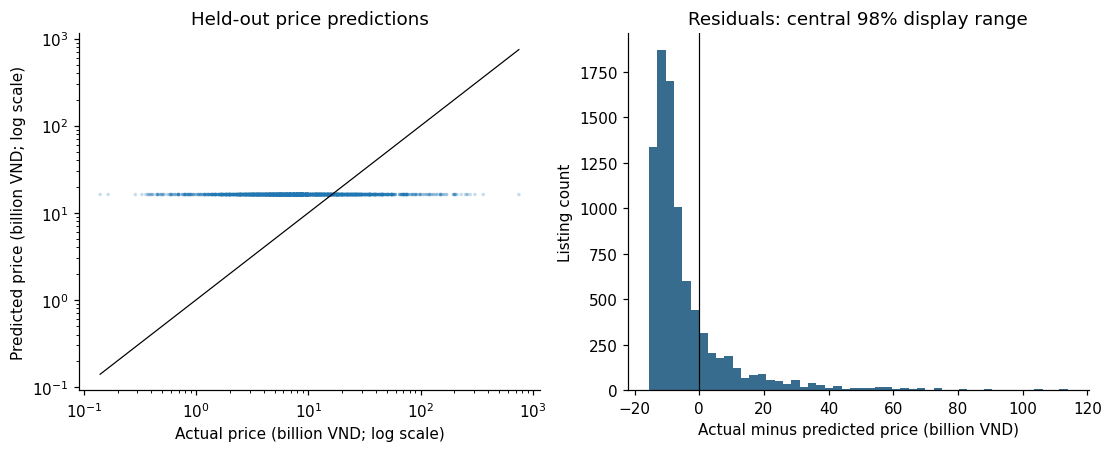

In [7]:
validation_prediction = predict_frame(model, validation)
test_prediction = predict_frame(model, test)
extra = {}

result, evaluation_table = record_result(
    "dummy", manifest, parts, validation_prediction, test_prediction,
    selected_parameters, tuning_results, extra=extra)
display(evaluation_table.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                      "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
diagnostics("dummy", test.price, test_prediction)

## 10. Results and Discussion

A constant predictor cannot represent geography, property type, or area. Its mean is sensitive to large recorded prices. Its role is a reference, not a deployable valuation model.

The comparison table contains only completed models with an identical protocol and split fingerprint. Missing or incompatible previous model results have no row until re-executed; no scores are imputed. The final summary audit requires all seven models to match. Rankings are descriptive for this cohort. They do not establish statistical significance or performance on verified sales.

In [8]:
comparison = comparison_table(manifest)
display(comparison.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                 "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
score = result["metrics"]["test"]
display(Markdown(
    f"The held-out test evaluation gives MAE **{score['MAE']:,.0f} VND**, "
    f"RMSE **{score['RMSE']:,.0f} VND**, R² **{score['R2']:.4f}**, "
    f"and MAPE **{score['MAPE']:,.2f}%**. These observed values describe "
    "the frozen temporal cohort and the recorded asking-price labels."
))

,Model,MAE,RMSE,R2,MAPE
0,Dummy Regressor,"45,548,775,416","2,966,493,482,061",-0.0001,259.20


The held-out test evaluation gives MAE **45,548,775,416 VND**, RMSE **2,966,493,482,061 VND**, R² **-0.0001**, and MAPE **259.20%**. These observed values describe the frozen temporal cohort and the recorded asking-price labels.

## 11. Conclusion

This notebook provides an executed, auditable estimate under the shared temporal protocol. Source checksums, split identity, candidate settings, environment versions, predictions, and original-scale metrics are recorded as artifacts. Interpretation is limited by sample-based training, a heuristic entity proxy, extreme or incorrectly extracted prices, incomplete attributes, possible mixed transaction types, and a single temporal holdout. A separate verified-sale dataset and repeated temporal backtesting are required before deployment or broad market claims.